# Video 12: Morphology versus molecular identity

Notes for this notebook.

This notebook generates the visuals for the twelfth video in the Multimodal Spatial Biology series. We already have cell area and nuclear intensity from segmentation, measurements that had no role in building the molecular clusters from Video 7. Here we ask directly, does looking different under the microscope actually predict being molecularly different, or not.

This notebook reuses the cluster assignments from Video 7. All output images are saved into outputs/video12.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [2]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video12")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video12


## Load clusters and working names

We reuse the five Leiden clusters and working names from Video 7 and Video 11.


In [3]:
df = pd.read_csv("outputs/video7/core01_hcc_clusters.csv")

cluster_names = {
    0: "Epithelial A",
    1: "Immune",
    2: "Stromal",
    3: "Epithelial B",
    4: "Lymphatic-like",
}
df["cell_type"] = df["leiden_cluster"].map(cluster_names)

print(df.groupby("cell_type")[["area_px", "DAPI_mean"]].agg(["mean", "std"]).round(1))


               area_px        DAPI_mean       
                  mean    std      mean    std
cell_type                                     
Epithelial A    1282.8  706.4     362.1  142.0
Epithelial B    1256.4  771.6     256.1  123.3
Immune           461.2  253.0     689.4  280.8
Lymphatic-like  1010.2  585.9     497.4  179.8
Stromal          646.3  418.7     361.4  205.4


## Do the five populations differ in size and density

Cell area and DAPI intensity were never used to build these clusters, only the sixteen protein markers were, with DAPI explicitly excluded. If these morphological measurements differ meaningfully between clusters anyway, that is independent evidence the molecular groupings correspond to real biological differences.


Kruskal-Wallis, area_px: statistic=2849.8, p=0.00e+00
Kruskal-Wallis, DAPI_mean: statistic=2838.2, p=0.00e+00


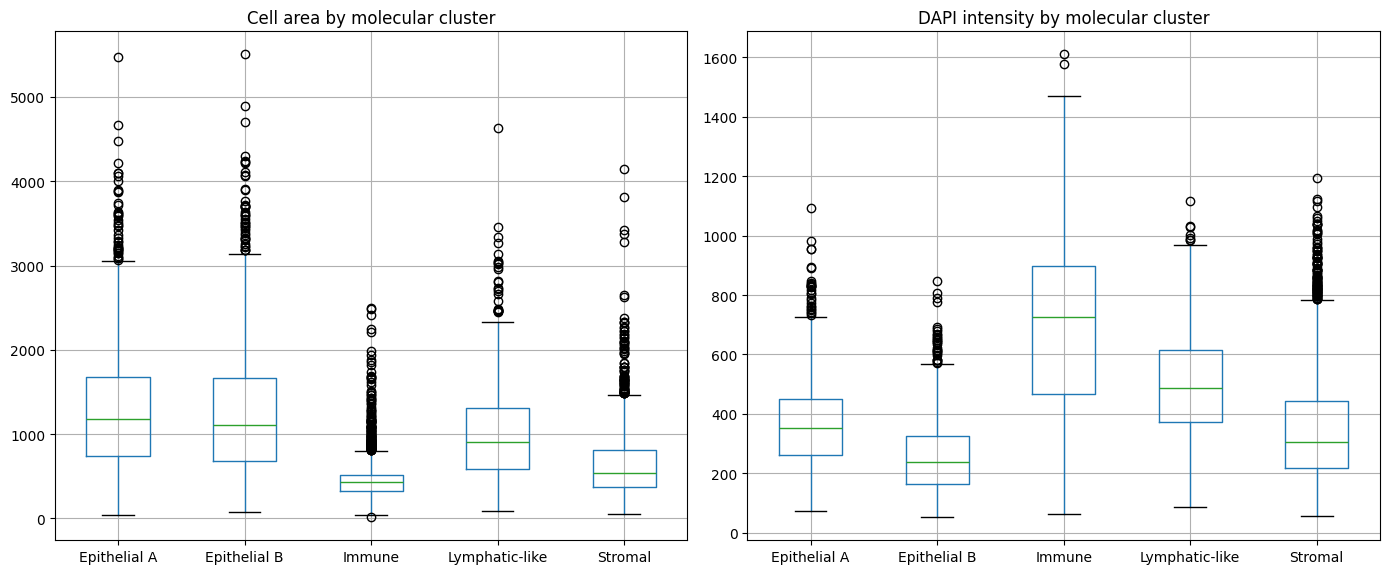

Saved slide_morphology_boxplots.png


In [4]:
from scipy.stats import kruskal

groups_area = [g["area_px"].values for _, g in df.groupby("cell_type")]
groups_dapi = [g["DAPI_mean"].values for _, g in df.groupby("cell_type")]

stat_area, p_area = kruskal(*groups_area)
stat_dapi, p_dapi = kruskal(*groups_dapi)
print(f"Kruskal-Wallis, area_px: statistic={stat_area:.1f}, p={p_area:.2e}")
print(f"Kruskal-Wallis, DAPI_mean: statistic={stat_dapi:.1f}, p={p_dapi:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
df.boxplot(column="area_px", by="cell_type", ax=axes[0])
axes[0].set_title("Cell area by molecular cluster")
axes[0].set_xlabel("")
df.boxplot(column="DAPI_mean", by="cell_type", ax=axes[1])
axes[1].set_title("DAPI intensity by molecular cluster")
axes[1].set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_morphology_boxplots.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_morphology_boxplots.png")


Both measurements differ significantly between clusters, with a very large sample size behind that result. Immune cells stand out clearly, smallest in area and highest in DAPI intensity, consistent with the small, dense nuclei typical of lymphocytes. The two epithelial populations are the largest, consistent with hepatocyte morphology.

A statistically significant difference across thousands of cells is not the same as a difference large enough to reliably tell individual cells apart. Let us look at that directly.


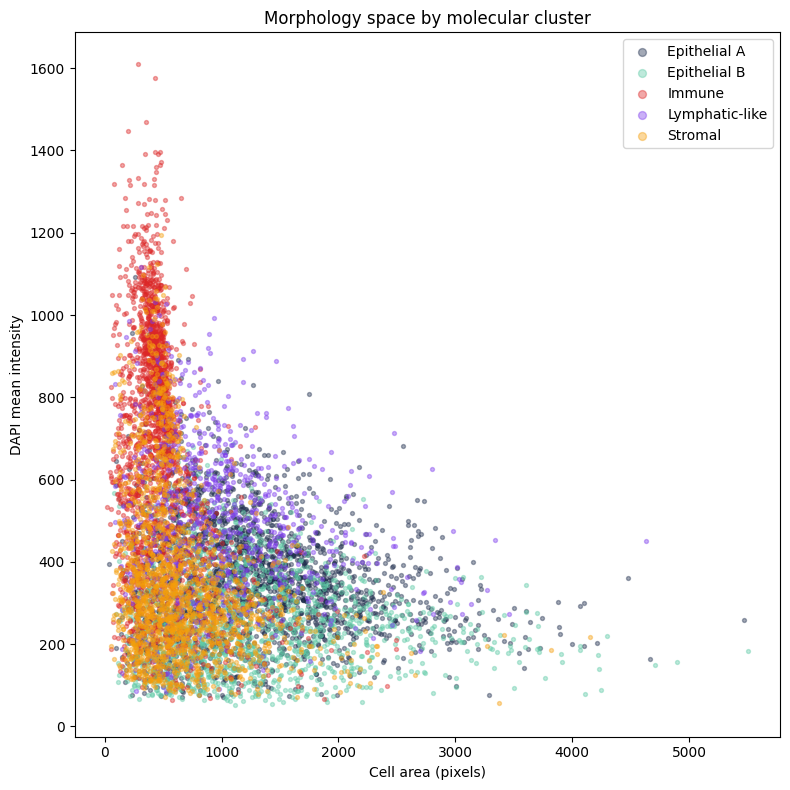

Saved slide_morphology_scatter.png


In [5]:
colors = {"Epithelial A": "#1B2A4A", "Epithelial B": "#5DCAA5", "Immune": "#DC2626",
          "Stromal": "#F59E0B", "Lymphatic-like": "#7C3AED"}

fig, ax = plt.subplots(figsize=(8, 8))
for cell_type, group in df.groupby("cell_type"):
    ax.scatter(group["area_px"], group["DAPI_mean"], s=8, alpha=0.4, label=cell_type, color=colors[cell_type])
ax.set_xlabel("Cell area (pixels)")
ax.set_ylabel("DAPI mean intensity")
ax.set_title("Morphology space by molecular cluster")
ax.legend(markerscale=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_morphology_scatter.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_morphology_scatter.png")


Visually, the five populations overlap heavily in this space. There is no clean separation into five distinct regions. Rather than judge this by eye, let us put an actual number on how well area and DAPI alone can predict molecular identity.


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

X = df[["area_px", "DAPI_mean"]].values
y = df["cell_type"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

clf = RandomForestClassifier(n_estimators=200, random_state=0)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
most_common = pd.Series(y_train).mode()[0]
baseline_acc = (y_test == most_common).mean()

print(f"Accuracy using only area and DAPI: {accuracy:.3f}")
print(f"Baseline, always predicting the most common class ({most_common}): {baseline_acc:.3f}")
print()
print(classification_report(y_test, y_pred))


Accuracy using only area and DAPI: 0.462
Baseline, always predicting the most common class (Epithelial A): 0.249

                precision    recall  f1-score   support

  Epithelial A       0.45      0.46      0.46       619
  Epithelial B       0.40      0.37      0.38       463
        Immune       0.65      0.67      0.66       613
Lymphatic-like       0.28      0.21      0.24       253
       Stromal       0.38      0.42      0.40       537

      accuracy                           0.46      2485
     macro avg       0.43      0.43      0.43      2485
  weighted avg       0.46      0.46      0.46      2485



## Reading this honestly

Morphology alone predicts molecular identity meaningfully better than chance, but far from perfectly. The story is uneven across populations, which is the most informative part of this result.

Immune cells classify well from morphology alone, consistent with their genuinely distinct size and nuclear density. Epithelial A, Epithelial B, and Stromal classify moderately, some real morphological difference exists, but with substantial overlap. The lymphatic-like population, the smallest and most recently discovered cluster in this series, classifies worst of all, despite being a real, spatially distinct population, confirmed independently in both Video 8 and Video 11, its morphology alone barely distinguishes it from everything else.

This is a meaningful result in its own right. Some genuine, biologically real cell populations are effectively invisible from morphology alone. The lymphatic-like population would likely never have been found from an H and E image or from cell shape and size measurements on their own, it only emerged because we had molecular markers available.


## Summary

Molecular clustering and morphology agree well for some cell types, particularly immune cells, and agree poorly for others, particularly the rarer, more recently discovered populations in this tissue. That unevenness is itself the finding, it shows directly why molecular, multimodal profiling adds real value beyond what imaging alone can provide, some biology is simply not visible without it.

This closes out the second arc of the Multimodal Spatial Biology series. Across these episodes, we validated our protein findings against an independent transcript modality, let unsupervised clustering define real cell populations, turned visual spatial patterns into actual statistics, found biology that only a large gene panel could reveal, and connected molecular identity back to cell morphology. A natural next step would be running this same pipeline across all four tissue cores in this dataset, tumor, non tumor liver, tonsil, and hepatocellular adenoma, to see how cell composition compares across genuinely different tissue types.
